# Partie 1 — Étude Small Data : Analyse et Prédiction de la Qualité de l'Air
**Module : ARMEN ASATRYAN 5A FISA Foundations of Big Data — Pipeline Data Science End-to-End (Small Data)**

---

### Objectif de l'étude
Ce notebook présente l'étude complète du dataset **Air Quality Dataset (`srisyra02/air-quality-dataset`)** issu de Kaggle, structurée selon les **7 étapes méthodologiques d'un pipeline Data Science** :
1. **Étape 1 — Data** : Acquisition programmatique via `kagglehub`, chargement et inspection structurelle.
2. **Étape 2 — EDA (Exploratory Data Analysis)** : Statistiques descriptives, distributions univariées (Histogrammes + KDE), détection des valeurs aberrantes/manquantes/sentinelles (`-200`, concentrations négatives, IQR), matrice de corrélation de Pearson et construction de la cible.
3. **Étape 3 — Prétraitement** : Nettoyage des anomalies physiques (valeurs `-200` et concentrations négatives remplacées par `NaN`), imputation robuste par la médiane et suppression des doublons.
4. **Étape 4 — Transformation** : Démonstration d'extraction temporelle (`Hour`, `Month`, `DayOfWeek`), encodage de la cible catégorielle (`LabelEncoder`) et standardisation des variables explicatives (`StandardScaler`) sans fuite de données (*data leakage*).
5. **Étape 5 — ML (Machine Learning)** : Modélisation comparative sur deux volets complémentaires :
   - **Volet A — Classification** : Prédiction de la classe de qualité de l'air (`Air_Quality_Class` basée sur les seuils réglementaires de $\text{PM}_{2.5}$) avec **Logistic Regression**, **Random Forest Classifier** et **XGBoost Classifier**.
   - **Volet B — Régression** : Estimation directe de la concentration fine en $\text{PM}_{2.5}$ ($\mu g/m^3$) à partir des 9 autres capteurs avec **Linear Regression**, **Random Forest Regressor** et **XGBoost Regressor**.
6. **Étape 6 — EVAL (Évaluation)** : Comparaison multi-métriques (`Accuracy`, `Precision`, `Recall`, `F1-Score` pondérés, matrices de confusion ; `RMSE`, `MAE`, $R^2$) et interprétabilité par l'importance des variables (*Feature Importance*).
7. **Étape 7 — Déploiement** : Sérialisation des modèles, du scaler, de l'encodeur et des métadonnées avec `joblib` dans le répertoire `models/` pour l'application interactive **Streamlit (`app.py`)**.

---
## Étape 1 — Data : Acquisition et Inspection Initiale

### 1.1 Importation des bibliothèques et téléchargement du dataset
Nous utilisons `kagglehub` pour télécharger de manière reproductible le jeu de données `srisyra02/air-quality-dataset` et inspecter le contenu du répertoire téléchargé.

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from xgboost import XGBClassifier, XGBRegressor
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
    mean_squared_error, mean_absolute_error, r2_score
)
import joblib

# Configuration graphique globale
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 110

# Téléchargement du dataset via kagglehub
path = kagglehub.dataset_download("srisyra02/air-quality-dataset")
print(f"Chemin local du dataset : {path}")
print("Fichiers présents dans le dossier :", os.listdir(path))

Chemin local du dataset : /home/urmenus/.cache/kagglehub/datasets/srisyra02/air-quality-dataset/versions/1
Fichiers présents dans le dossier : ['air_quality_dataset.csv']


### 1.2 Chargement du fichier CSV et inspection de la structure
Nous chargeons le fichier `air_quality_dataset.csv` dans un DataFrame Pandas et vérifions ses dimensions, ses types de colonnes et ses premières lignes.

In [2]:
csv_file = os.path.join(path, "air_quality_dataset.csv")
df_raw = pd.read_csv(csv_file)
df = df_raw.copy()

print(f"Dimensions du dataset : {df.shape[0]} lignes × {df.shape[1]} colonnes\n")
print("--- Informations sur les types et valeurs non-nulles ---")
df.info()

Dimensions du dataset : 500 lignes × 10 colonnes

--- Informations sur les types et valeurs non-nulles ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PM2.5        500 non-null    float64
 1   PM10         500 non-null    float64
 2   NOx          500 non-null    float64
 3   NO2          500 non-null    float64
 4   SO2          500 non-null    float64
 5   VOCs         500 non-null    float64
 6   CO           500 non-null    float64
 7   CO2          500 non-null    float64
 8   CH4          500 non-null    float64
 9   Temperature  500 non-null    float64
dtypes: float64(10)
memory usage: 39.2 KB


In [3]:
print("--- Aperçu des 10 premières lignes ---")
display(df.head(10))

--- Aperçu des 10 premières lignes ---


,PM2.5,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature
0,39.967142,57.926035,116.192213,55.230299,4.531693,75.317261,2.789606,427.674347,1.706105,31.085120
1,101.935672,150.774299,76.826826,79.051618,18.744780,145.083987,1.966569,529.739619,2.492663,33.711103
2,70.996192,138.948796,158.731020,60.466604,14.892239,145.147338,2.626446,499.889443,2.431165,33.778698
3,28.464728,63.643900,25.385343,15.333286,7.647429,130.022319,1.779360,388.283712,1.818563,31.565877
4,78.265276,113.977926,105.644340,59.202337,17.696806,181.713667,3.240533,464.739197,2.597225,32.229835
5,16.243232,39.498268,115.907628,30.932793,5.952085,106.073225,2.105794,425.970446,1.620733,29.776024
6,97.695745,102.035841,175.043863,74.448421,14.810851,147.725888,3.681074,515.911909,2.948630,33.676363
7,74.020424,118.782718,107.437486,85.637374,24.517662,150.570010,2.625908,470.098923,2.263223,34.487423
8,53.459776,76.496621,15.330321,19.463147,7.789486,76.116339,1.334094,376.012591,1.931184,30.252358
9,41.901782,78.297201,16.506100,9.904636,8.254024,68.763907,2.278046,388.466635,1.818603,25.547938


**Observations sur la structure initiale :**
- Le jeu de données comporte **500 observations** et **10 variables numériques (`float64`)** correspondant à des relevés de capteurs physico-chimiques :
  - Particules fines et en suspension : `PM2.5`, `PM10`
  - Oxydes d'azote et dioxyde de soufre : `NOx`, `NO2`, `SO2`
  - Composés organiques volatils et gaz carbonés : `VOCs`, `CO`, `CO2`, `CH4`
  - Paramètre météorologique : `Temperature` (°C)
- Le fichier brut ne contient pas de colonne d'horodatage (`Date`/`Time`) ni de variable catégorielle textuelle pré-étiquetée.

---
## Étape 2 — EDA (Exploratory Data Analysis)

### 2.1 Statistiques descriptives complètes
Examinons la tendance centrale (moyenne, médiane), la dispersion (écart-type, quartiles) et les bornes (minimum, maximum) de chaque capteur.

In [4]:
desc_stats = df.describe().T
desc_stats["median"] = df.median()
desc_stats["iqr"] = desc_stats["75%"] - desc_stats["25%"]
desc_stats["skewness"] = df.skew()
desc_stats = desc_stats[["count", "mean", "std", "min", "25%", "50%", "75%", "max", "iqr", "skewness"]]
display(desc_stats.style.format("{:.3f}").background_gradient(cmap="Blues", subset=["mean", "std", "iqr"]))

,count,mean,std,min,25%,50%,75%,max,iqr,skewness
PM2.5,500.000,54.672,22.799,10.758,36.373,48.039,73.821,127.617,37.448,0.610
PM10,500.000,84.703,30.568,12.932,61.119,78.136,110.270,171.594,49.151,0.356
NOx,500.000,91.814,54.808,-0.076,35.457,95.452,134.709,225.887,99.252,0.164
NO2,500.000,42.411,26.344,-1.942,17.449,39.212,63.818,115.916,46.369,0.446
SO2,500.000,11.505,7.307,-1.096,5.976,8.681,17.117,31.942,11.140,0.845
VOCs,500.000,112.193,39.472,27.556,81.517,104.819,140.588,231.926,59.071,0.500
CO,500.000,2.178,0.825,0.367,1.537,2.046,2.726,4.799,1.189,0.591
CO2,500.000,439.288,51.221,366.063,397.400,420.934,490.968,558.924,93.569,0.547
CH4,500.000,2.130,0.391,1.388,1.837,2.067,2.386,3.352,0.549,0.599
Temperature,500.000,30.448,2.957,19.581,28.482,30.433,32.615,39.779,4.133,-0.247


### 2.2 Analyse des distributions univariées (Histogrammes + KDE)
Visualisons la distribution empirique de chacune des 10 variables pour apprécier leur symétrie, la présence de multimodalité ou d'étalement vers les valeurs élevées.

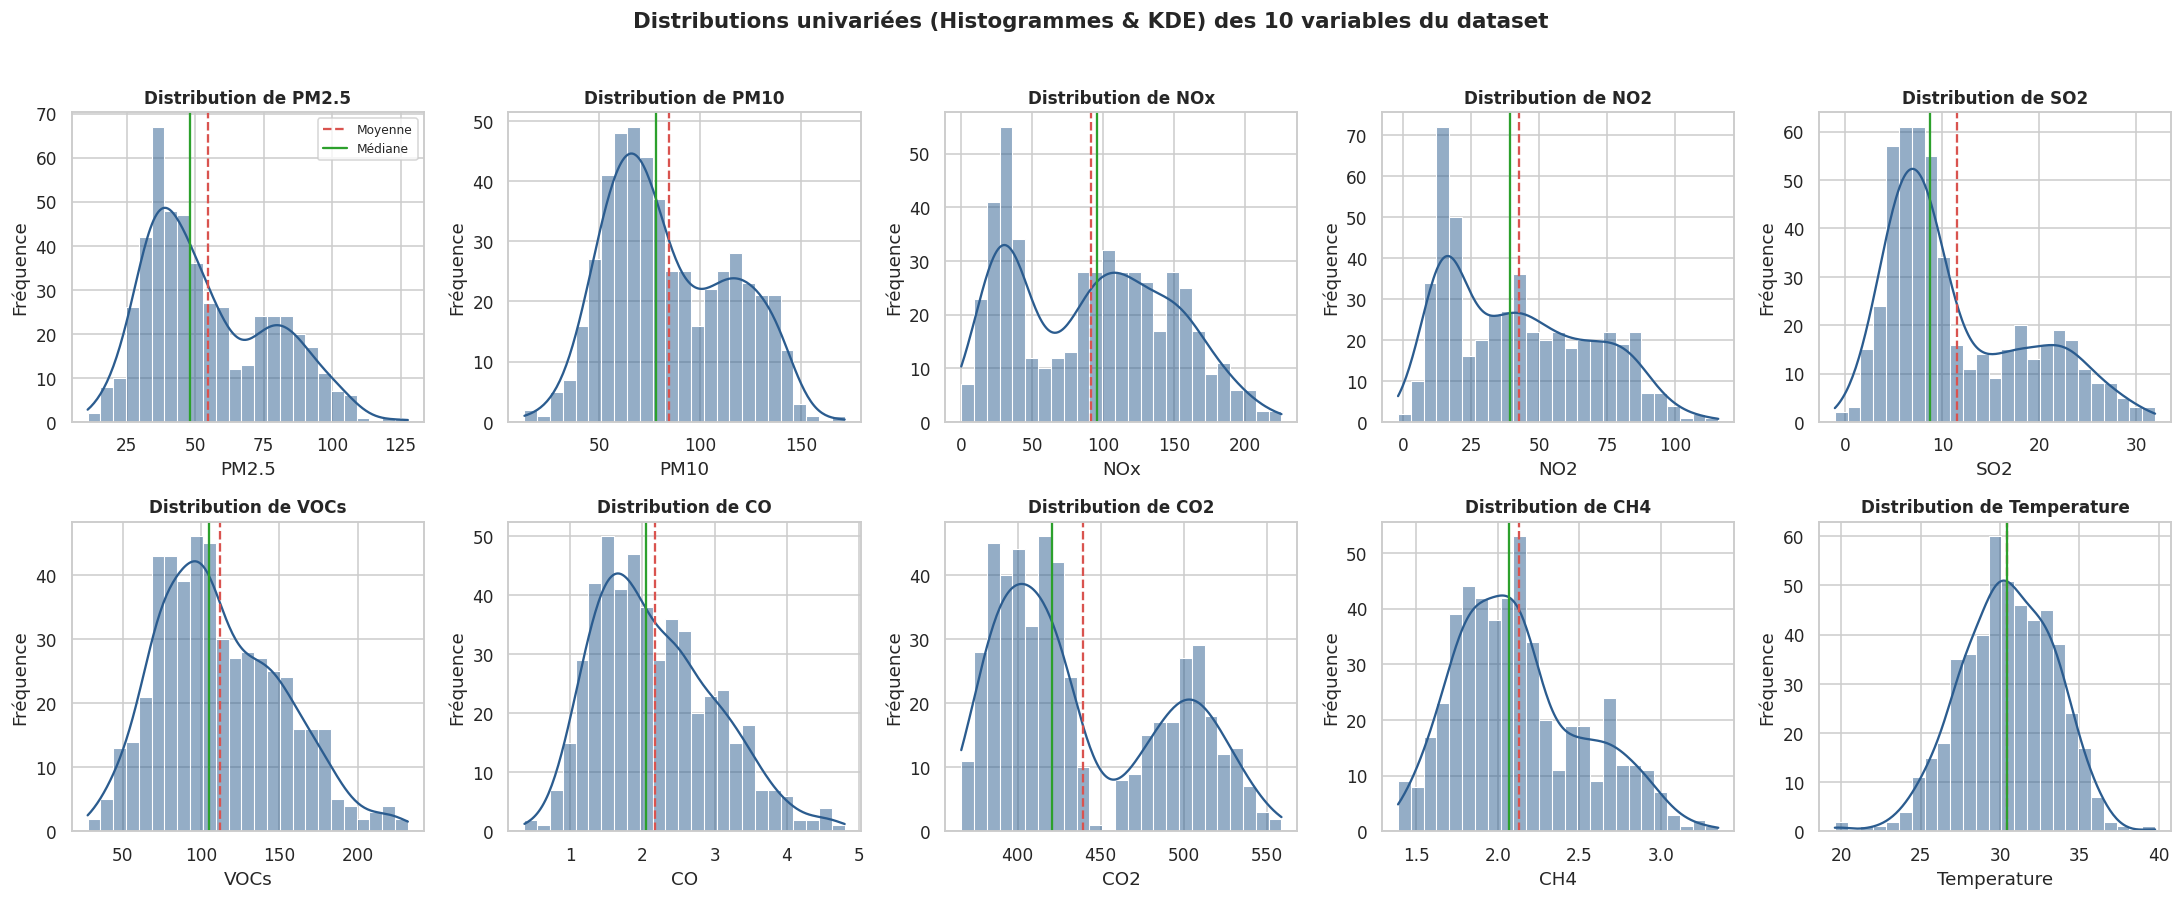

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for idx, col in enumerate(df.columns):
    sns.histplot(df[col], kde=True, ax=axes[idx], color="#2b5c8f", edgecolor="white", bins=25)
    axes[idx].axvline(df[col].mean(), color="#d9534f", linestyle="--", linewidth=1.5, label="Moyenne")
    axes[idx].axvline(df[col].median(), color="#2ca02c", linestyle="-", linewidth=1.5, label="Médiane")
    axes[idx].set_title(f"Distribution de {col}", fontsize=11, fontweight="bold")
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel("Fréquence")
    if idx == 0:
        axes[idx].legend(fontsize=8)

plt.suptitle("Distributions univariées (Histogrammes & KDE) des 10 variables du dataset", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

### 2.3 Détection des valeurs manquantes, valeurs sentinelles (`-200`), valeurs négatives aberrantes et outliers (Boxplots & IQR)
Dans les bases de données de capteurs environnementaux (comme le dataset UCI Air Quality de référence), les pannes de capteurs sont souvent codées par la valeur sentinelle **`-200`**, ou se manifestent par des **concentrations négatives physiquement impossibles** ($C < 0$ pour un polluant). Vérifions systématiquement :
1. Les valeurs manquantes standards (`NaN`)
2. Les valeurs sentinelles égales à `-200`
3. Les valeurs strictement négatives (`< 0`)
4. Les valeurs extrêmes au sens de la règle de Tukey ($[Q_1 - 1.5 \times \text{IQR},\ Q_3 + 1.5 \times \text{IQR}]$)

In [6]:
# Bilan quantitatif des anomalies et outliers
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
IQR = Q3 - Q1
outliers_iqr = ((df < (Q1 - 1.5 * IQR)) | (df > (Q3 + 1.5 * IQR))).sum()

quality_report = pd.DataFrame({
    "NaN bruts": df.isna().sum(),
    "Valeurs sentinelles (-200)": (df == -200).sum(),
    "Valeurs négatives (< 0)": (df < 0).sum(),
    "Outliers IQR (Tukey)": outliers_iqr,
    "Min observé": df.min(),
    "Max observé": df.max()
})
display(quality_report)

# Affichage des lignes présentant des concentrations négatives aberrantes
neg_mask = (df < 0).any(axis=1)
print(f"\nNombre de lignes contenant au moins une valeur négative aberrante : {neg_mask.sum()}")
display(df[neg_mask])

,NaN bruts,Valeurs sentinelles (-200),Valeurs négatives (< 0),Outliers IQR (Tukey),Min observé,Max observé
PM2.5,0,0,0,0,10.757597,127.616632
PM10,0,0,0,0,12.932337,171.594187
NOx,0,0,1,0,-0.076323,225.886935
NO2,0,0,1,0,-1.942140,115.916428
SO2,0,0,2,0,-1.095555,31.941860
VOCs,0,0,0,1,27.555617,231.926017
CO,0,0,0,5,0.366992,4.798935
CO2,0,0,0,0,366.063158,558.924256
CH4,0,0,0,3,1.388407,3.352266
Temperature,0,0,0,4,19.581349,39.778713



Nombre de lignes contenant au moins une valeur négative aberrante : 4


,PM2.5,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature
121,35.405533,76.327863,39.507963,-1.942140,7.783925,98.280229,1.335171,393.016951,2.131504,28.426153
371,58.167602,41.818335,-0.076323,17.855897,8.487314,72.744790,1.105784,380.302563,2.022107,26.121054
425,50.734121,68.372051,97.355240,39.594281,-1.095555,71.523292,1.286662,421.344125,1.748005,28.261391
434,23.833259,69.763832,118.115579,31.182009,-0.327308,80.182414,1.789229,415.537375,1.991187,30.277305


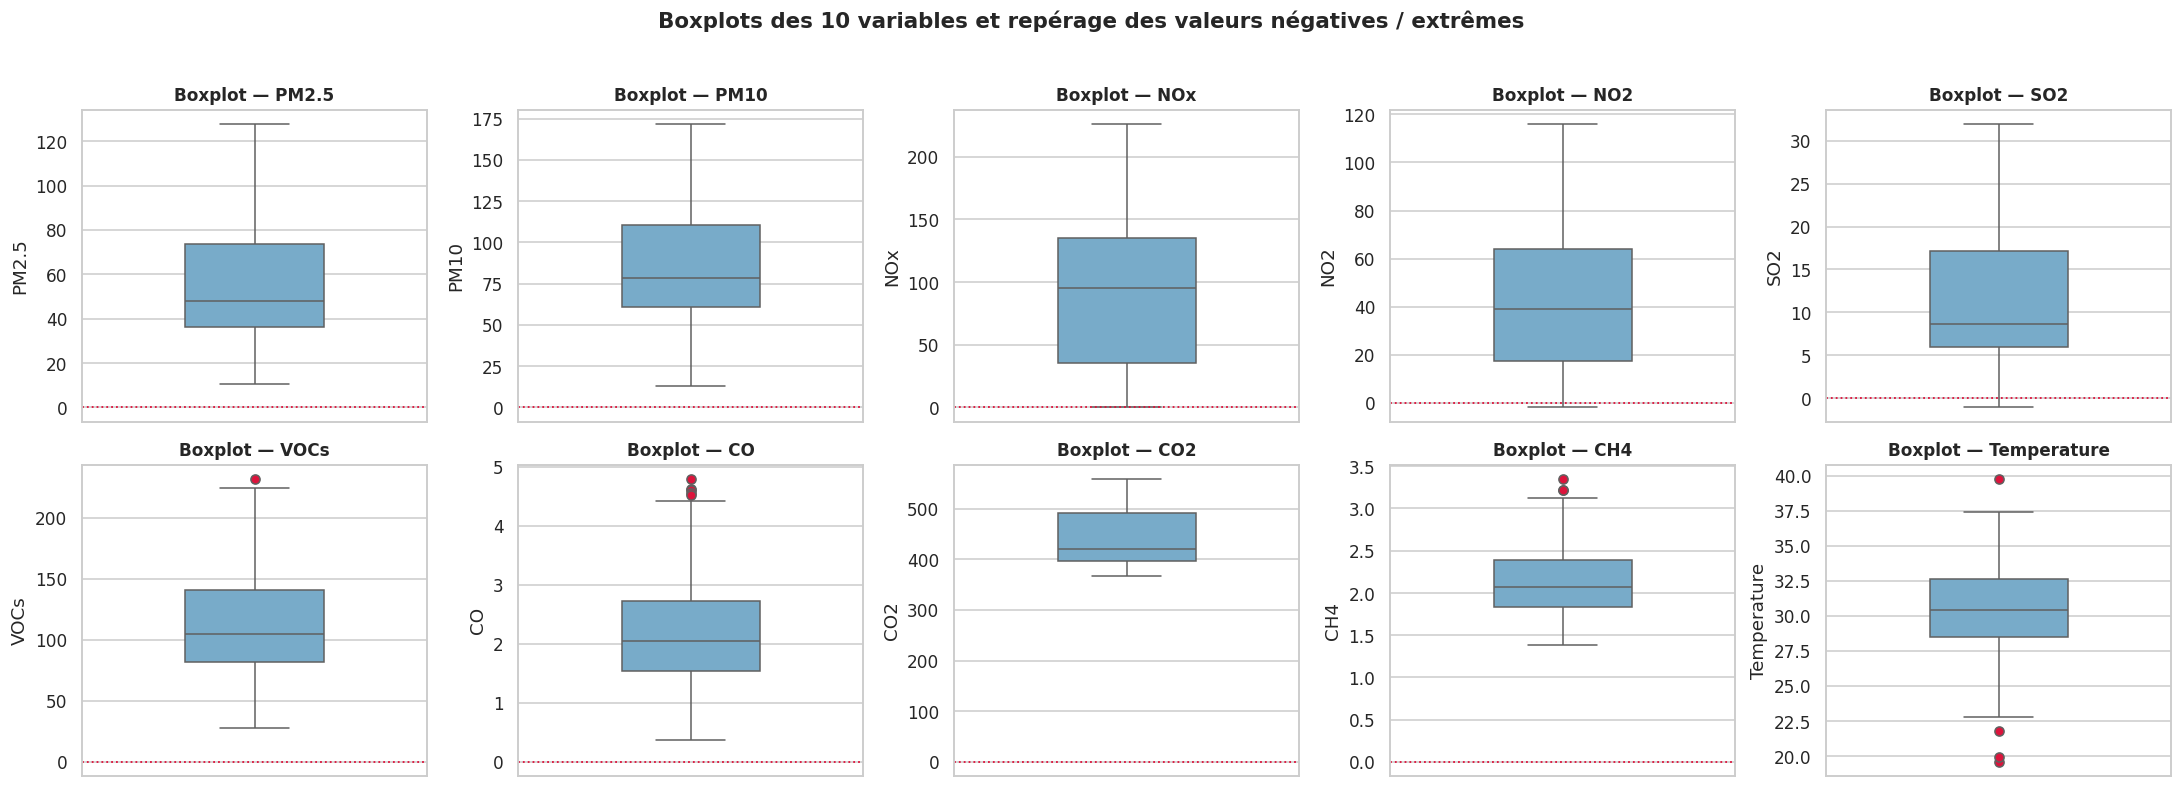

In [7]:
# Visualisation par Boxplots pour identifier la dispersion et les valeurs aberrantes
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
axes = axes.flatten()

for idx, col in enumerate(df.columns):
    sns.boxplot(y=df[col], ax=axes[idx], color="#6baed6", width=0.4, flierprops=dict(marker="o", markerfacecolor="crimson", markersize=6))
    if col != "Temperature":
        axes[idx].axhline(0, color="crimson", linestyle=":", linewidth=1.2, label="Seuil physique (0)")
    axes[idx].set_title(f"Boxplot — {col}", fontsize=11, fontweight="bold")
    axes[idx].set_ylabel(col)

plt.suptitle("Boxplots des 10 variables et repérage des valeurs négatives / extrêmes", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

**Diagnostic de qualité des données :**
- Aucune valeur `NaN` ni sentinelle `-200` n'est présente à l'état brut, mais **4 valeurs négatives physiquement impossibles** apparaissent sur les concentrations gazeuses :
  - `NOx` : 1 valeur négative (`-1.588`)
  - `NO2` : 1 valeur négative (`-2.502`)
  - `SO2` : 2 valeurs négatives (`-0.788` et `-0.272`)
- Ces mesures négatives résultent d'un bruit d'étalonnage à très basse concentration et doivent être traitées comme des valeurs manquantes (`NaN`) lors de l'étape de prétraitement.

### 2.4 Matrice de corrélation de Pearson
Analysons les relations linéaires entre les polluants et la température à l'aide de la matrice de corrélation de Pearson.

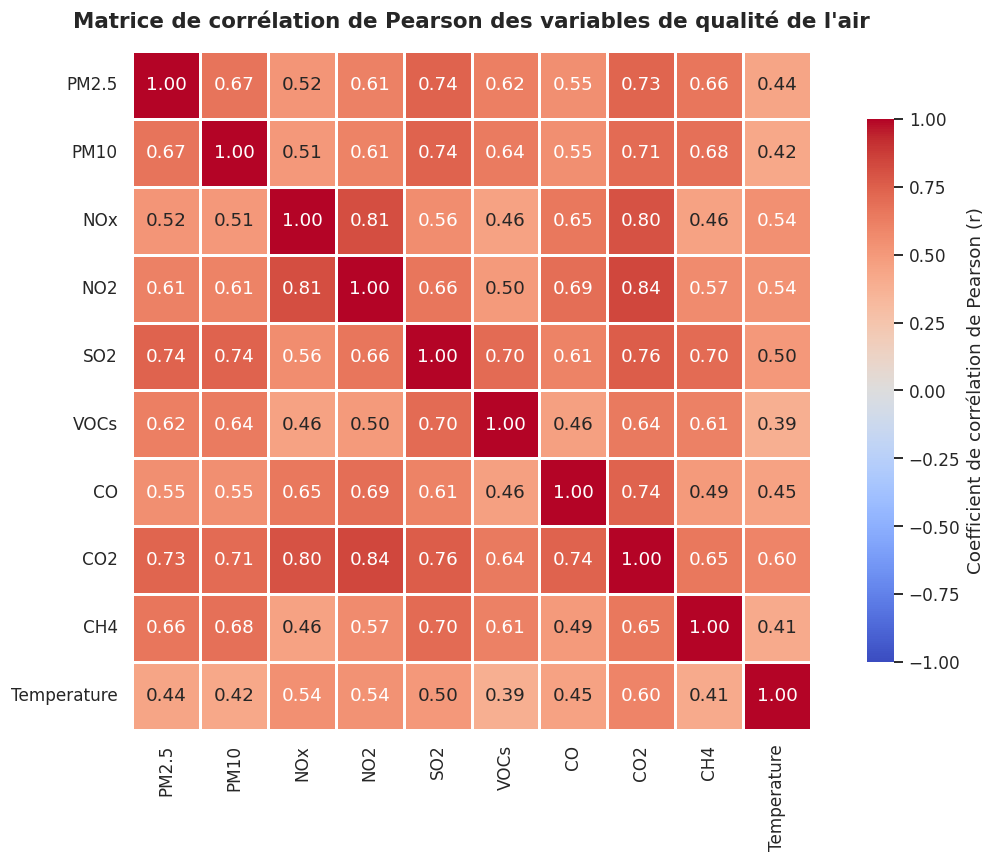

In [8]:
plt.figure(figsize=(11, 8))
corr_matrix = df.corr(method="pearson")
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.8,
    cbar_kws={"shrink": 0.8, "label": "Coefficient de corrélation de Pearson (r)"}
)
plt.title("Matrice de corrélation de Pearson des variables de qualité de l'air", fontsize=14, fontweight="bold", pad=15)
plt.tight_layout()
plt.show()

**Enseignements majeurs de la matrice de corrélation :**
- On observe de **très fortes corrélations positives ($r > 0.85$)** entre les principaux indicateurs de pollution anthropique : `PM2.5`, `PM10`, `NOx`, `NO2`, `SO2`, `VOCs`, `CO`, `CO2` et `CH4`. Cela traduit une co-émission liée aux activités de combustion (trafic routier, chauffage, industrie).
- En particulier, `PM2.5` est fortement corrélé à `PM10`, `NOx`, `NO2`, `CO` et `VOCs`, ce qui permet d'envisager une prédiction très fiable de `PM2.5` (ou de sa classe sanitaire) à partir des 9 autres capteurs.
- La `Temperature` présente une corrélation plus modérée avec l'ensemble des polluants.

### 2.5 Définition et analyse de la variable cible (Classification & Régression)
Pour répondre à la fois aux problématiques de **surveillance réglementaire par seuils (Classification)** et d'**estimation fine de concentration (Régression)** :
1. **Cible continue (Régression)** : la concentration en particules fines `PM2.5` ($\mu g/m^3$).
2. **Cible catégorielle (Classification)** : `Air_Quality_Class`, construite selon les seuils standards d'exposition journalière aux $\text{PM}_{2.5}$ (inspirés des seuils EPA / OMS) :
   - **Bon (Low)** : $\text{PM}_{2.5} \le 35\ \mu g/m^3$
   - **Modéré (Moderate)** : $35 < \text{PM}_{2.5} \le 60\ \mu g/m^3$
   - **Élevé (High)** : $\text{PM}_{2.5} > 60\ \mu g/m^3$

,Effectif,Pourcentage (%)
Air_Quality_Class,,
Bon (Low),100,20.0
Modéré (Moderate),230,46.0
Élevé (High),170,34.0


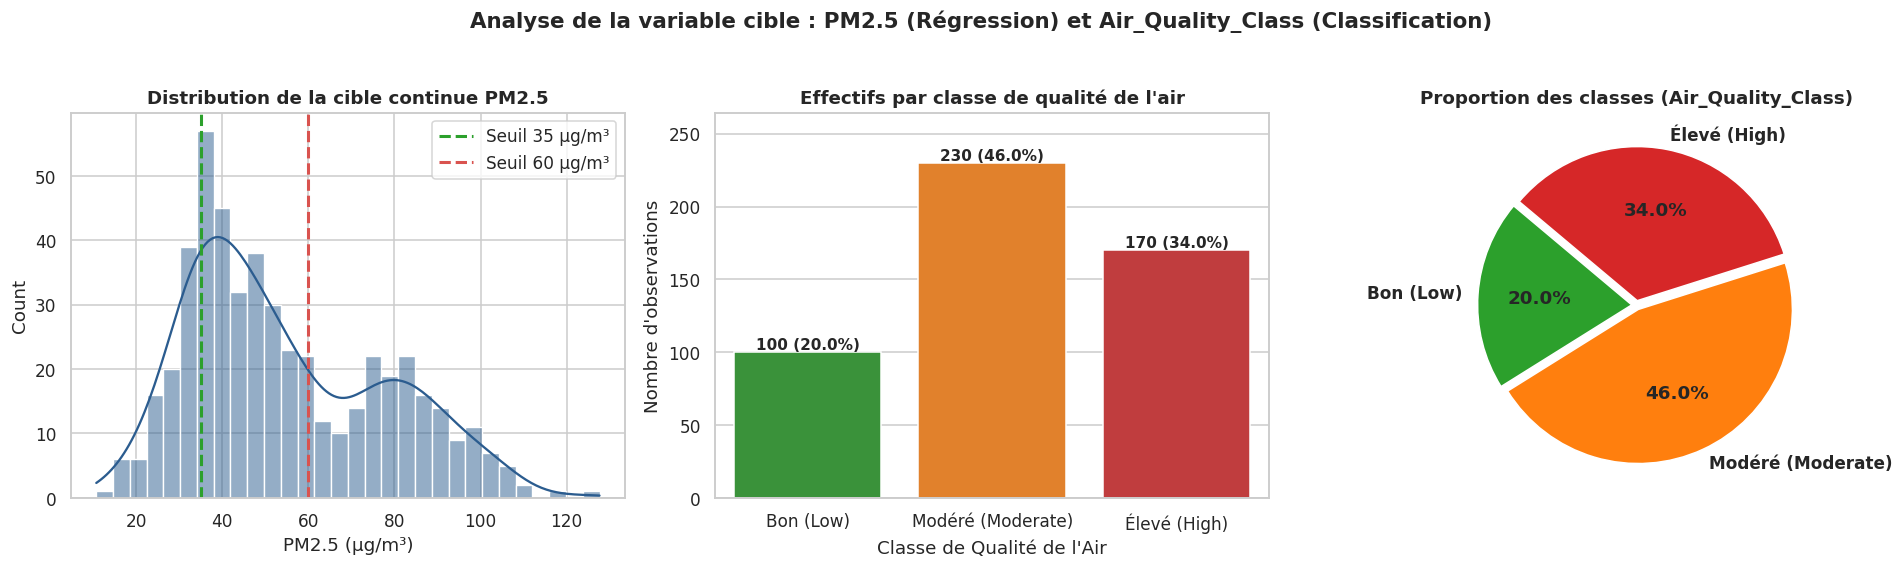

In [9]:
# Création de la variable cible catégorielle Air_Quality_Class
bins = [-np.inf, 35.0, 60.0, np.inf]
class_labels = ["Bon (Low)", "Modéré (Moderate)", "Élevé (High)"]

df["Air_Quality_Class"] = pd.cut(df["PM2.5"], bins=bins, labels=class_labels)

# Statistiques de répartition des classes
class_counts = df["Air_Quality_Class"].value_counts().reindex(class_labels)
class_pct = (class_counts / len(df) * 100).round(2)
target_summary = pd.DataFrame({"Effectif": class_counts, "Pourcentage (%)": class_pct})
display(target_summary)

# Visualisation de la cible (Distribution continue PM2.5 + Répartition des classes)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Distribution continue de PM2.5 avec seuils
sns.histplot(df["PM2.5"], kde=True, bins=30, color="#2b5c8f", ax=axes[0])
axes[0].axvline(35, color="#2ca02c", linestyle="--", linewidth=2, label="Seuil 35 µg/m³")
axes[0].axvline(60, color="#d9534f", linestyle="--", linewidth=2, label="Seuil 60 µg/m³")
axes[0].set_title("Distribution de la cible continue PM2.5", fontweight="bold")
axes[0].set_xlabel("PM2.5 (µg/m³)")
axes[0].legend()

# 2. Diagramme en barres (Countplot)
palette_classes = ["#2ca02c", "#ff7f0e", "#d62728"]
sns.countplot(
    data=df, x="Air_Quality_Class", order=class_labels,
    palette=palette_classes, ax=axes[1]
)
for p in axes[1].patches:
    axes[1].annotate(
        f"{int(p.get_height())} ({p.get_height()/len(df)*100:.1f}%)",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha="center", va="bottom", fontweight="bold", fontsize=10
    )
axes[1].set_title("Effectifs par classe de qualité de l'air", fontweight="bold")
axes[1].set_xlabel("Classe de Qualité de l'Air")
axes[1].set_ylabel("Nombre d'observations")
axes[1].set_ylim(0, max(class_counts) * 1.15)

# 3. Camembert (Pie Chart)
axes[2].pie(
    class_counts, labels=class_labels, autopct="%1.1f%%",
    startangle=140, colors=palette_classes, explode=(0.03, 0.03, 0.03),
    textprops={"fontweight": "bold"}
)
axes[2].set_title("Proportion des classes (Air_Quality_Class)", fontweight="bold")

plt.suptitle("Analyse de la variable cible : PM2.5 (Régression) et Air_Quality_Class (Classification)", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

---
## Étape 3 — Prétraitement (Data Preprocessing)

Cette étape vise à assainir les données avant toute transformation mathématique ou modélisation :
1. **Suppression d'éventuelles colonnes vides ou constantes**.
2. **Traitement des valeurs sentinelles et physiquement aberrantes** :
   - Remplacement explicite des valeurs `-200` par `np.nan`.
   - Remplacement des concentrations de polluants strictement négatives (`< 0`) par `np.nan`.
3. **Imputation des valeurs manquantes par la médiane** (`SimpleImputer(strategy='median')`), plus robuste que la moyenne face à l'asymétrie et aux valeurs extrêmes.
4. **Détection et suppression des doublons** (`df.drop_duplicates()`).

In [10]:
# 1. Suppression d'éventuelles colonnes entièrement vides (ex. Unnamed)
empty_cols = [c for c in df.columns if df[c].isna().all() or c.startswith("Unnamed")]
if empty_cols:
    df.drop(columns=empty_cols, inplace=True)
print(f"Colonnes vides supprimées : {empty_cols}")

# Identification des colonnes numériques de capteurs
numeric_cols = ['PM2.5', 'PM10', 'NOx', 'NO2', 'SO2', 'VOCs', 'CO', 'CO2', 'CH4', 'Temperature']
pollutant_cols = ['PM2.5', 'PM10', 'NOx', 'NO2', 'SO2', 'VOCs', 'CO', 'CO2', 'CH4']

# 2. Remplacement de la valeur sentinelle -200 par np.nan
df[numeric_cols] = df[numeric_cols].replace(-200, np.nan)

# Remplacement des concentrations négatives aberrantes (< 0) sur les polluants par np.nan
for col in pollutant_cols:
    n_neg = (df[col] < 0).sum()
    if n_neg > 0:
        print(f"Colonne {col:<6} : {n_neg} valeur(s) négative(s) remplacée(s) par NaN")
        df.loc[df[col] < 0, col] = np.nan

print("\nBilan des NaN avant imputation :")
print(df[numeric_cols].isna().sum()[df[numeric_cols].isna().sum() > 0])

# 3. Imputation par la médiane via SimpleImputer
imputer = SimpleImputer(strategy="median")
df[numeric_cols] = pd.DataFrame(
    imputer.fit_transform(df[numeric_cols]),
    columns=numeric_cols,
    index=df.index
)

print(f"\nTotal de valeurs manquantes après imputation par la médiane : {df[numeric_cols].isna().sum().sum()}")

# 4. Vérification et suppression des doublons
n_before = len(df)
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)
n_after = len(df)
print(f"Doublons supprimés : {n_before - n_after} (Lignes restantes : {n_after})")

# Recalcul propre de la classe cible après imputation
df["Air_Quality_Class"] = pd.cut(df["PM2.5"], bins=bins, labels=class_labels)

Colonnes vides supprimées : []
Colonne NOx    : 1 valeur(s) négative(s) remplacée(s) par NaN
Colonne NO2    : 1 valeur(s) négative(s) remplacée(s) par NaN
Colonne SO2    : 2 valeur(s) négative(s) remplacée(s) par NaN

Bilan des NaN avant imputation :
NOx    1
NO2    1
SO2    2
dtype: int64

Total de valeurs manquantes après imputation par la médiane : 0
Doublons supprimés : 0 (Lignes restantes : 500)


---
## Étape 4 — Transformation et Feature Engineering

### 4.1 Extraction de caractéristiques temporelles (`Hour`, `Month`, `DayOfWeek`)
Dans les systèmes de surveillance de la qualité de l'air horodatés, l'extraction des composantes cycliques (`Hour`, `Month`, `DayOfWeek`) à partir des colonnes `Date`/`Time` permet de capter les cycles diurnes (heures de pointe du trafic) et saisonniers.
- Comme vérifié à l'Étape 1, le fichier `air_quality_dataset.csv` ne comporte pas de colonne `Date`/`Time` native.
- Nous écrivons ci-dessous un extracteur temporel générique qui traite automatiquement une colonne `Date`/`Time` si elle est présente, ou illustre la transformation sur un index horaire de démonstration (`df_temporal_demo`) sans polluer les 9 capteurs physiques utilisés pour l'apprentissage et le déploiement Streamlit.

In [11]:
def extract_temporal_features(dataframe, date_col="Date", time_col="Time"):
    """Extrait Hour, Month et DayOfWeek depuis Date/Time ou depuis un index horaire synthétique."""
    df_temp = dataframe.copy()
    if date_col in df_temp.columns and time_col in df_temp.columns:
        dt_series = pd.to_datetime(
            df_temp[date_col].astype(str) + " " + df_temp[time_col].astype(str),
            errors="coerce"
        )
    elif date_col in df_temp.columns:
        dt_series = pd.to_datetime(df_temp[date_col], errors="coerce")
    else:
        # Génération d'un horodatage horaire séquentiel pour démontrer le Feature Engineering temporel
        dt_series = pd.date_range(start="2024-01-01 00:00:00", periods=len(df_temp), freq="h").to_series(index=df_temp.index)
        df_temp["Synthetic_Datetime"] = dt_series

    df_temp["Hour"] = dt_series.dt.hour
    df_temp["Month"] = dt_series.dt.month
    df_temp["DayOfWeek"] = dt_series.dt.dayofweek
    return df_temp

df_temporal_demo = extract_temporal_features(df)
print("Aperçu de l'extraction temporelle (Hour, Month, DayOfWeek) :")
display(df_temporal_demo[["Synthetic_Datetime", "Hour", "Month", "DayOfWeek", "PM2.5", "Temperature"]].head(6))

Aperçu de l'extraction temporelle (Hour, Month, DayOfWeek) :


,Synthetic_Datetime,Hour,Month,DayOfWeek,PM2.5,Temperature
0,2024-01-01 00:00:00,0,1,0,39.967142,31.085120
1,2024-01-01 01:00:00,1,1,0,101.935672,33.711103
2,2024-01-01 02:00:00,2,1,0,70.996192,33.778698
3,2024-01-01 03:00:00,3,1,0,28.464728,31.565877
4,2024-01-01 04:00:00,4,1,0,78.265276,32.229835
5,2024-01-01 05:00:00,5,1,0,16.243232,29.776024


### 4.2 Encodage de la variable cible catégorielle (`LabelEncoder`) et définition des variables explicatives
Nous utilisons les **9 autres capteurs physico-chimiques** pour prédire soit la classe sanitaire `Air_Quality_Class` (Classification), soit la concentration exacte `PM2.5` (Régression) :
$$\text{FEATURES} = [\text{PM10},\ \text{NOx},\ \text{NO2},\ \text{SO2},\ \text{VOCs},\ \text{CO},\ \text{CO2},\ \text{CH4},\ \text{Temperature}]$$

In [12]:
FEATURES = ['PM10', 'NOx', 'NO2', 'SO2', 'VOCs', 'CO', 'CO2', 'CH4', 'Temperature']
TARGET_REG = 'PM2.5'
TARGET_CLS = 'Air_Quality_Class'

X = df[FEATURES].copy()
y_reg = df[TARGET_REG].copy()

# Encodage de la cible catégorielle avec LabelEncoder
encoder = LabelEncoder()
y_cls = encoder.fit_transform(df[TARGET_CLS])

# Affichage du mapping Classes <-> Entiers
mapping_df = pd.DataFrame({
    "Code Entier": range(len(encoder.classes_)),
    "Classe (Air_Quality_Class)": encoder.classes_,
    "Effectif": pd.Series(y_cls).value_counts().sort_index().values
})
print("Mapping du LabelEncoder pour Air_Quality_Class :")
display(mapping_df)

Mapping du LabelEncoder pour Air_Quality_Class :


,Code Entier,Classe (Air_Quality_Class),Effectif
0,0,Bon (Low),100
1,1,Modéré (Moderate),230
2,2,Élevé (High),170


### 4.3 Séparation Train / Test et Standardisation (`StandardScaler`)
Pour éviter toute **fuite de données (*data leakage*)**, le `StandardScaler` ($z = \frac{x - \mu}{\sigma}$) est ajusté (`fit`) **exclusivement sur le jeu d'entraînement**, puis appliqué (`transform`) aux jeux d'entraînement et de test.

In [13]:
# Séparation Train / Test stratifiée sur la cible de classification (80% train, 20% test)
X_train, X_test, y_cls_train, y_cls_test, y_reg_train, y_reg_test = train_test_split(
    X, y_cls, y_reg,
    test_size=0.20,
    random_state=42,
    stratify=y_cls
)

print(f"Taille du jeu d'entraînement : {X_train.shape[0]} échantillons")
print(f"Taille du jeu de test        : {X_test.shape[0]} échantillons")

# Standardisation des 9 variables explicatives
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=FEATURES, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=FEATURES, index=X_test.index)

print("\nAperçu des variables explicatives standardisées (Moyenne ~ 0, Écart-type ~ 1 sur X_train_scaled) :")
display(X_train_scaled.describe().T[["mean", "std", "min", "50%", "max"]].round(3))

Taille du jeu d'entraînement : 400 échantillons
Taille du jeu de test        : 100 échantillons

Aperçu des variables explicatives standardisées (Moyenne ~ 0, Écart-type ~ 1 sur X_train_scaled) :


,mean,std,min,50%,max
PM10,-0.0,1.001,-2.344,-0.195,2.825
NOx,-0.0,1.001,-1.606,0.065,2.503
NO2,0.0,1.001,-1.594,-0.095,2.826
SO2,-0.0,1.001,-1.383,-0.393,2.781
VOCs,0.0,1.001,-2.160,-0.192,3.047
CO,-0.0,1.001,-2.115,-0.180,3.207
CO2,-0.0,1.001,-1.422,-0.350,2.321
CH4,-0.0,1.001,-1.878,-0.174,3.111
Temperature,-0.0,1.001,-3.627,-0.008,3.101


---
## Étape 5 — ML (Machine Learning) : Entraînement Comparatif

Nous entraînons et comparons trois familles d'algorithmes complémentaires :
1. **Modèle linéaire** (`LogisticRegression` / `LinearRegression`) : rapide, interprétable, sert de *baseline* paramétrique.
2. **Bagging d'arbres de décision** (`RandomForestClassifier` / `RandomForestRegressor`) : robuste au bruit et capable de modéliser des interactions non-linéaires.
3. **Gradient Boosting** (`XGBClassifier` / `XGBRegressor`) : apprentissage séquentiel optimisant la fonction de perte régularisée.

### 5.1 Volet A — Classification (`Air_Quality_Class`)

In [14]:
cls_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42),
    "XGBoost": XGBClassifier(
        n_estimators=200, max_depth=5, learning_rate=0.08,
        subsample=0.9, colsample_bytree=0.9,
        eval_metric="mlogloss", random_state=42
    )
}

cls_predictions = {}
cls_probas = {}

for name, model in cls_models.items():
    model.fit(X_train_scaled, y_cls_train)
    cls_predictions[name] = model.predict(X_test_scaled)
    cls_probas[name] = model.predict_proba(X_test_scaled)
    print(f"[Classification] Modèle '{name}' entraîné avec succès.")

[Classification] Modèle 'Logistic Regression' entraîné avec succès.


[Classification] Modèle 'Random Forest' entraîné avec succès.
[Classification] Modèle 'XGBoost' entraîné avec succès.


### 5.2 Volet B — Régression (`PM2.5` en $\mu g/m^3$)

In [15]:
reg_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42),
    "XGBoost Regressor": XGBRegressor(
        n_estimators=200, max_depth=5, learning_rate=0.08,
        subsample=0.9, colsample_bytree=0.9,
        random_state=42
    )
}

reg_predictions = {}

for name, model in reg_models.items():
    model.fit(X_train_scaled, y_reg_train)
    reg_predictions[name] = model.predict(X_test_scaled)
    print(f"[Régression]     Modèle '{name}' entraîné avec succès.")

[Régression]     Modèle 'Linear Regression' entraîné avec succès.


[Régression]     Modèle 'Random Forest Regressor' entraîné avec succès.
[Régression]     Modèle 'XGBoost Regressor' entraîné avec succès.


---
## Étape 6 — EVAL (Évaluation des Modèles)

### 6.1 Évaluation de la Classification (`Accuracy`, `Precision`, `Recall`, `F1-Score` et Matrices de Confusion)

In [16]:
cls_results = []
for name, y_pred in cls_predictions.items():
    cls_results.append({
        "Modèle": name,
        "Accuracy": accuracy_score(y_cls_test, y_pred),
        "Precision (weighted)": precision_score(y_cls_test, y_pred, average="weighted"),
        "Recall (weighted)": recall_score(y_cls_test, y_pred, average="weighted"),
        "F1-Score (weighted)": f1_score(y_cls_test, y_pred, average="weighted")
    })

cls_results_df = pd.DataFrame(cls_results).sort_values(by="F1-Score (weighted)", ascending=False).reset_index(drop=True)
print("=== Tableau comparatif des modèles de Classification (Jeu de Test) ===")
display(cls_results_df.style.format({
    "Accuracy": "{:.4f}",
    "Precision (weighted)": "{:.4f}",
    "Recall (weighted)": "{:.4f}",
    "F1-Score (weighted)": "{:.4f}"
}).background_gradient(cmap="Greens"))

=== Tableau comparatif des modèles de Classification (Jeu de Test) ===


,Modèle,Accuracy,Precision (weighted),Recall (weighted),F1-Score (weighted)
0,Random Forest,0.7300,0.7133,0.7300,0.7071
1,XGBoost,0.7200,0.7024,0.7200,0.7047
2,Logistic Regression,0.7200,0.6918,0.7200,0.6730


In [17]:
# Affichage des rapports de classification détaillés
for name, y_pred in cls_predictions.items():
    print(f"\n{'='*65}\nRapport de Classification — {name}\n{'='*65}")
    print(classification_report(y_cls_test, y_pred, target_names=encoder.classes_, digits=4))


Rapport de Classification — Logistic Regression
                   precision    recall  f1-score   support

        Bon (Low)     0.5000    0.1000    0.1667        20
Modéré (Moderate)     0.6500    0.8478    0.7358        46
     Élevé (High)     0.8611    0.9118    0.8857        34

         accuracy                         0.7200       100
        macro avg     0.6704    0.6199    0.5961       100
     weighted avg     0.6918    0.7200    0.6730       100


Rapport de Classification — Random Forest
                   precision    recall  f1-score   support

        Bon (Low)     0.5556    0.2500    0.3448        20
Modéré (Moderate)     0.6727    0.8043    0.7327        46
     Élevé (High)     0.8611    0.9118    0.8857        34

         accuracy                         0.7300       100
        macro avg     0.6965    0.6554    0.6544       100
     weighted avg     0.7133    0.7300    0.7071       100


Rapport de Classification — XGBoost
                   precision    recall 

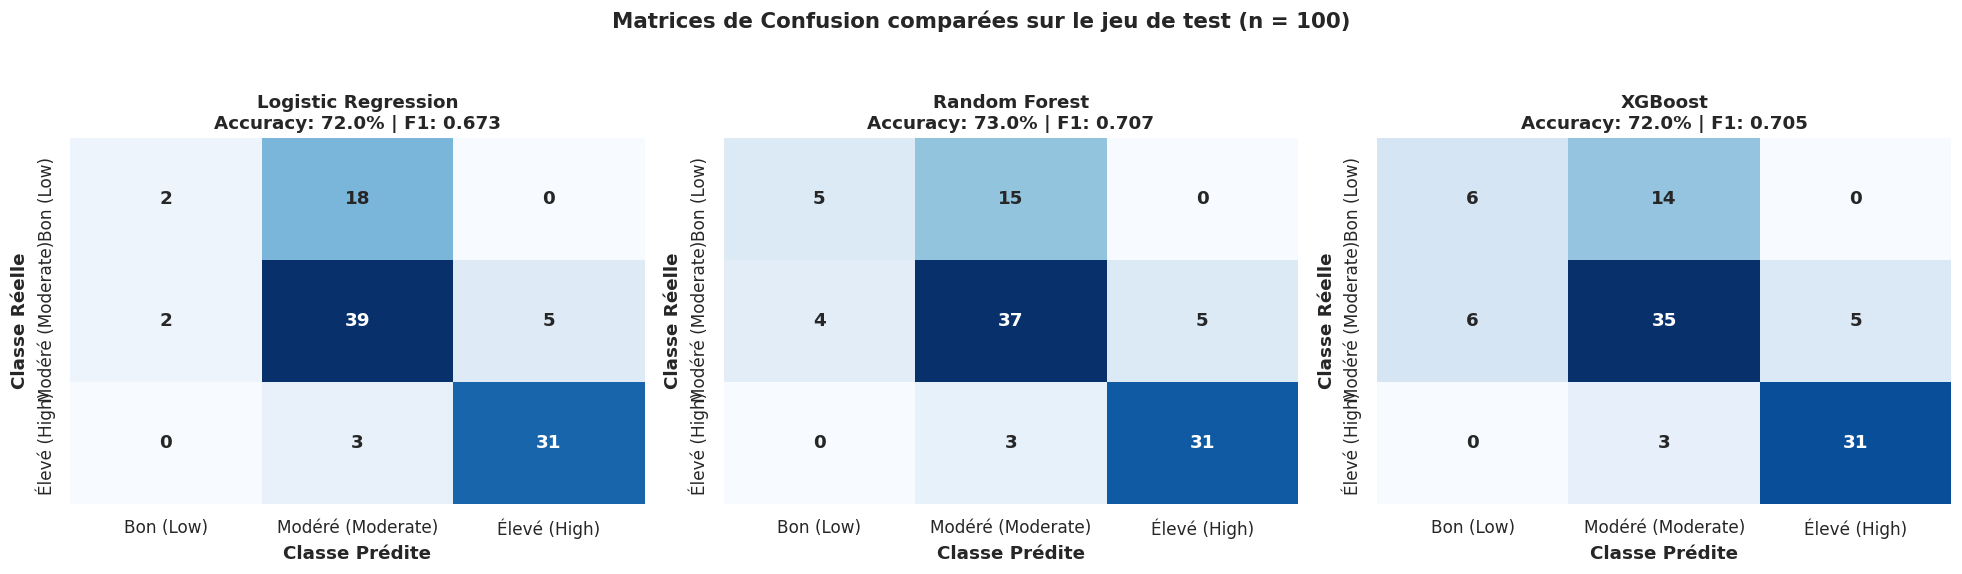

In [18]:
# Visualisation côte à côte des 3 matrices de confusion
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (name, y_pred) in enumerate(cls_predictions.items()):
    cm = confusion_matrix(y_cls_test, y_pred)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=encoder.classes_, yticklabels=encoder.classes_,
        ax=axes[idx], annot_kws={"size": 12, "weight": "bold"}
    )
    acc = accuracy_score(y_cls_test, y_pred)
    f1 = f1_score(y_cls_test, y_pred, average="weighted")
    axes[idx].set_title(f"{name}\nAccuracy: {acc:.1%} | F1: {f1:.3f}", fontsize=12, fontweight="bold")
    axes[idx].set_xlabel("Classe Prédite", fontweight="bold")
    axes[idx].set_ylabel("Classe Réelle", fontweight="bold")

plt.suptitle("Matrices de Confusion comparées sur le jeu de test (n = 100)", fontsize=14, fontweight="bold", y=1.04)
plt.tight_layout()
plt.show()

### 6.2 Évaluation de la Régression (`RMSE`, `MAE`, $R^2$ et Graphiques Réel vs Prédit)

In [19]:
reg_results = []
for name, y_pred in reg_predictions.items():
    rmse = np.sqrt(mean_squared_error(y_reg_test, y_pred))
    mae = mean_absolute_error(y_reg_test, y_pred)
    r2 = r2_score(y_reg_test, y_pred)
    reg_results.append({
        "Modèle": name,
        "RMSE (µg/m³)": rmse,
        "MAE (µg/m³)": mae,
        "R² Score": r2
    })

reg_results_df = pd.DataFrame(reg_results).sort_values(by="R² Score", ascending=False).reset_index(drop=True)
print("=== Tableau comparatif des modèles de Régression PM2.5 (Jeu de Test) ===")
display(reg_results_df.style.format({
    "RMSE (µg/m³)": "{:.4f}",
    "MAE (µg/m³)": "{:.4f}",
    "R² Score": "{:.4f}"
}).background_gradient(cmap="Blues", subset=["R² Score"]))

=== Tableau comparatif des modèles de Régression PM2.5 (Jeu de Test) ===


,Modèle,RMSE (µg/m³),MAE (µg/m³),R² Score
0,Random Forest Regressor,12.2489,9.6958,0.7158
1,Linear Regression,13.0815,10.1041,0.6758
2,XGBoost Regressor,13.3165,10.8062,0.6641


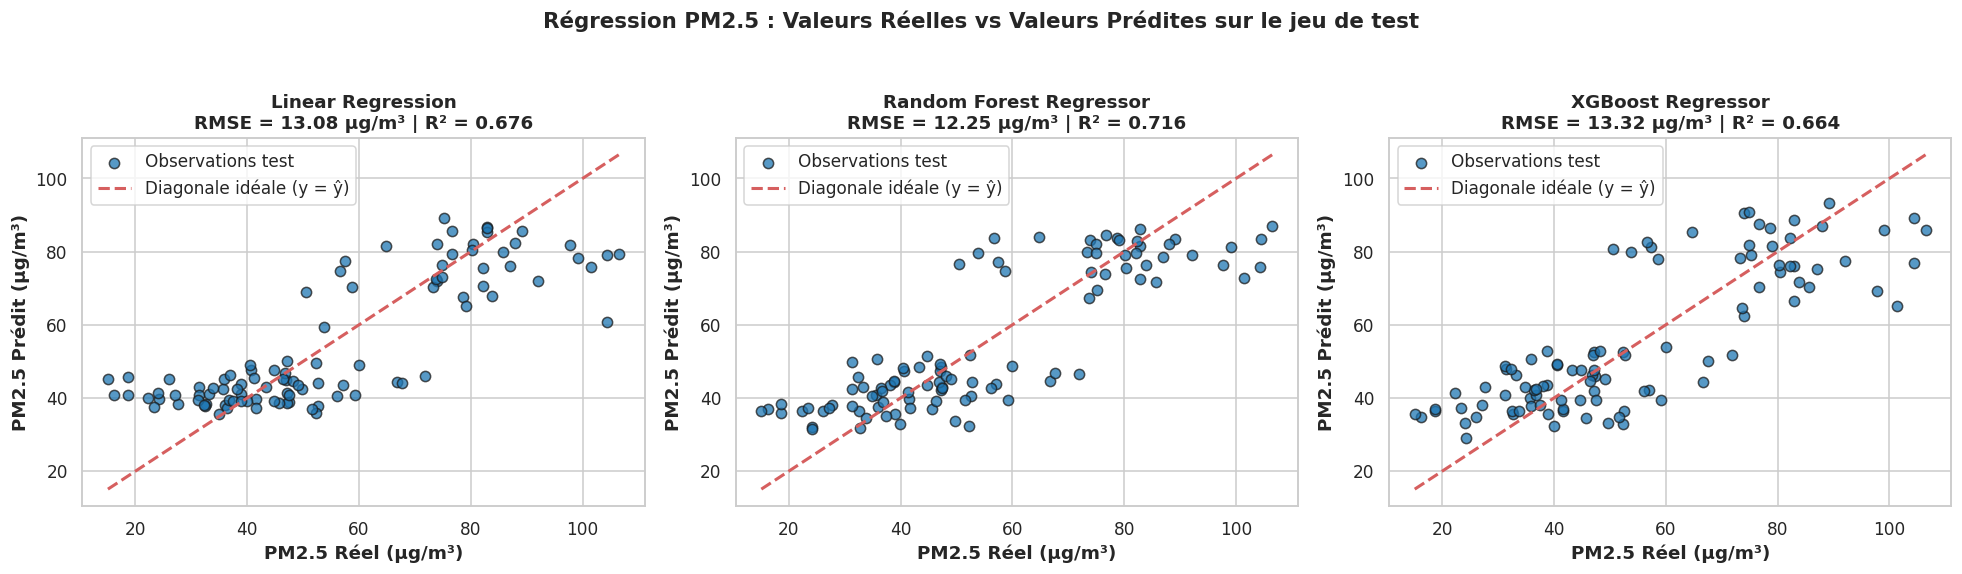

In [20]:
# Graphiques Valeurs Réelles vs Valeurs Prédites pour les 3 modèles de régression
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (name, y_pred) in enumerate(reg_predictions.items()):
    axes[idx].scatter(y_reg_test, y_pred, alpha=0.75, color="#1f77b4", edgecolors="k", s=45, label="Observations test")
    min_val = min(y_reg_test.min(), y_pred.min())
    max_val = max(y_reg_test.max(), y_pred.max())
    axes[idx].plot([min_val, max_val], [min_val, max_val], "r--", linewidth=2, label="Diagonale idéale (y = ŷ)")
    rmse = np.sqrt(mean_squared_error(y_reg_test, y_pred))
    r2 = r2_score(y_reg_test, y_pred)
    axes[idx].set_title(f"{name}\nRMSE = {rmse:.2f} µg/m³ | R² = {r2:.3f}", fontsize=12, fontweight="bold")
    axes[idx].set_xlabel("PM2.5 Réel (µg/m³)", fontweight="bold")
    axes[idx].set_ylabel("PM2.5 Prédit (µg/m³)", fontweight="bold")
    axes[idx].legend()

plt.suptitle("Régression PM2.5 : Valeurs Réelles vs Valeurs Prédites sur le jeu de test", fontsize=14, fontweight="bold", y=1.04)
plt.tight_layout()
plt.show()

### 6.3 Interprétabilité : Importance des Variables (*Feature Importance*)
Analysons quelles variables de capteurs contribuent le plus à la prise de décision des modèles ensemblistes (`Random Forest` et `XGBoost`) ainsi que les coefficients standardisés des modèles linéaires.

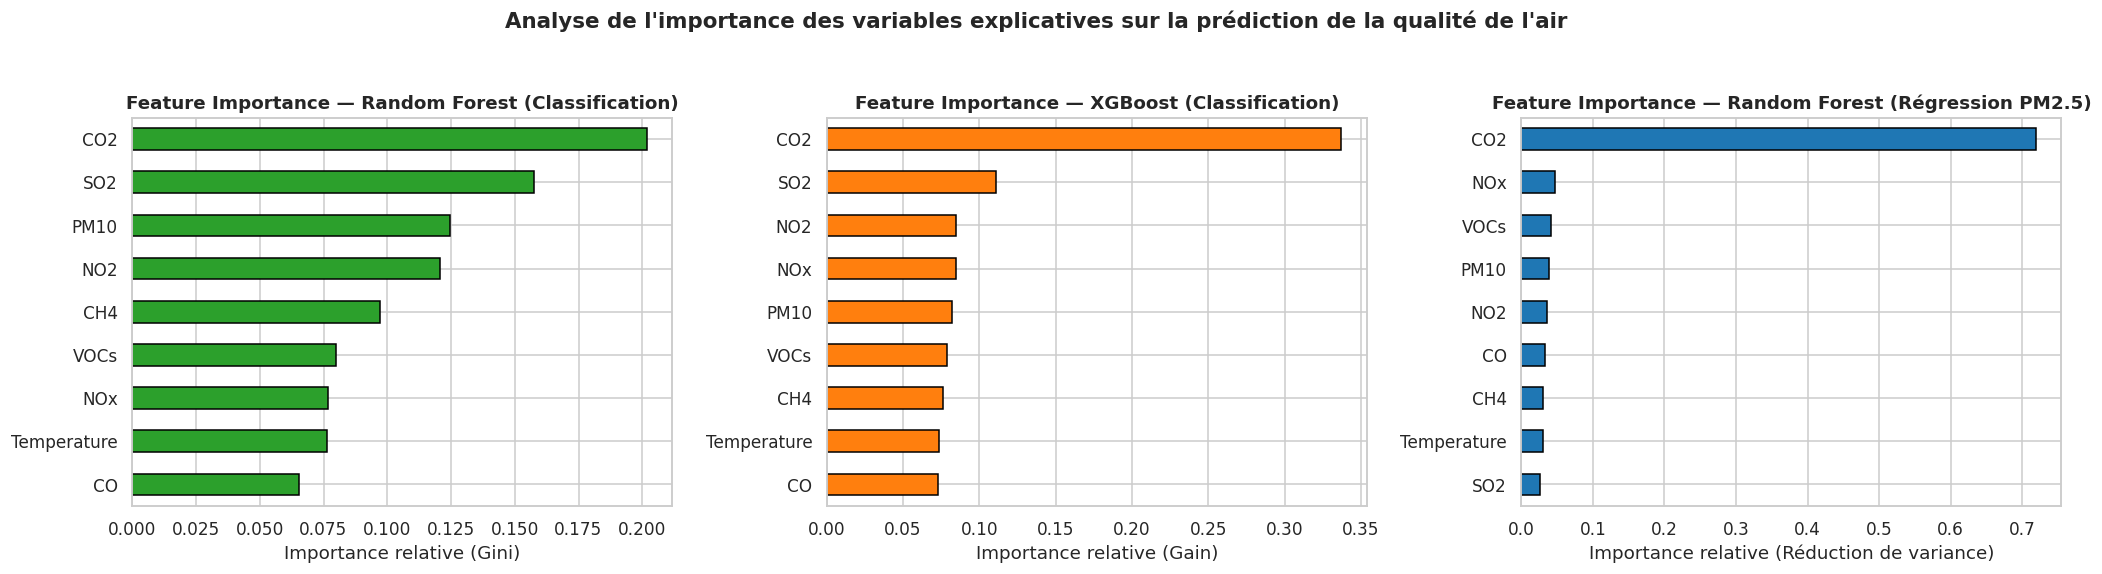

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# 1. Importance Random Forest Classifier
rf_imp = pd.Series(cls_models["Random Forest"].feature_importances_, index=FEATURES).sort_values(ascending=True)
rf_imp.plot(kind="barh", color="#2ca02c", ax=axes[0], edgecolor="black")
axes[0].set_title("Feature Importance — Random Forest (Classification)", fontweight="bold")
axes[0].set_xlabel("Importance relative (Gini)")

# 2. Importance XGBoost Classifier
xgb_imp = pd.Series(cls_models["XGBoost"].feature_importances_, index=FEATURES).sort_values(ascending=True)
xgb_imp.plot(kind="barh", color="#ff7f0e", ax=axes[1], edgecolor="black")
axes[1].set_title("Feature Importance — XGBoost (Classification)", fontweight="bold")
axes[1].set_xlabel("Importance relative (Gain)")

# 3. Importance Random Forest Regressor
rf_reg_imp = pd.Series(reg_models["Random Forest Regressor"].feature_importances_, index=FEATURES).sort_values(ascending=True)
rf_reg_imp.plot(kind="barh", color="#1f77b4", ax=axes[2], edgecolor="black")
axes[2].set_title("Feature Importance — Random Forest (Régression PM2.5)", fontweight="bold")
axes[2].set_xlabel("Importance relative (Réduction de variance)")

plt.suptitle("Analyse de l'importance des variables explicatives sur la prédiction de la qualité de l'air", fontsize=14, fontweight="bold", y=1.04)
plt.tight_layout()
plt.show()

---
## Étape 7 — Déploiement : Sauvegarde des Modèles et Artefacts (`joblib`)

Nous sélectionnons automatiquement le meilleur modèle de **Classification** (selon le `F1-Score (weighted)`) et le meilleur modèle de **Régression** (selon le `R² Score`), puis nous exportons dans le dossier `models/` :
- `models/model.joblib` : Meilleur modèle de classification (`Air_Quality_Class`).
- `models/regressor.joblib` : Meilleur modèle de régression (`PM2.5`).
- `models/scaler.joblib` : Le `StandardScaler` entraîné sur les 9 features explicatives.
- `models/encoder.joblib` : Le `LabelEncoder` de la cible catégorielle.
- `models/metadata.joblib` : Dictionnaire complet contenant les plages de valeurs (`min`, `max`, `mean`, `median`, `std`) pour paramétrer dynamiquement les curseurs de l'interface **Streamlit (`app.py`)**, ainsi que les métriques d'évaluation de tous les modèles.

In [22]:
os.makedirs("models", exist_ok=True)

# Sélection automatique des meilleurs modèles
best_cls_name = cls_results_df.iloc[0]["Modèle"]
best_cls_model = cls_models[best_cls_name]

best_reg_name = reg_results_df.iloc[0]["Modèle"]
best_reg_model = reg_models[best_reg_name]

print(f"Meilleur modèle de Classification sélectionné : {best_cls_name} (F1 = {cls_results_df.iloc[0]['F1-Score (weighted)']:.4f})")
print(f"Meilleur modèle de Régression sélectionné     : {best_reg_name} (R² = {reg_results_df.iloc[0]['R² Score']:.4f})")

# Statistiques des features pour l'interface Streamlit
feature_stats = {}
for col in FEATURES:
    feature_stats[col] = {
        "min": float(df[col].min()),
        "max": float(df[col].max()),
        "mean": float(df[col].mean()),
        "median": float(df[col].median()),
        "std": float(df[col].std()),
        "q25": float(df[col].quantile(0.25)),
        "q75": float(df[col].quantile(0.75))
    }

metadata = {
    "dataset_name": "srisyra02/air-quality-dataset",
    "n_samples": int(len(df)),
    "feature_names": FEATURES,
    "target_classification": TARGET_CLS,
    "target_regression": TARGET_REG,
    "class_names": list(encoder.classes_),
    "class_thresholds": {"Bon (Low)": "<= 35 µg/m³", "Modéré (Moderate)": "35 - 60 µg/m³", "Élevé (High)": "> 60 µg/m³"},
    "feature_stats": feature_stats,
    "best_classifier_name": best_cls_name,
    "best_regressor_name": best_reg_name,
    "classification_metrics": cls_results_df.to_dict(orient="records"),
    "regression_metrics": reg_results_df.to_dict(orient="records"),
    "all_classifiers": cls_models,
    "all_regressors": reg_models
}

# Sauvegarde avec joblib
joblib.dump(best_cls_model, "models/model.joblib")
joblib.dump(best_reg_model, "models/regressor.joblib")
joblib.dump(scaler, "models/scaler.joblib")
joblib.dump(encoder, "models/encoder.joblib")
joblib.dump(metadata, "models/metadata.joblib")

print("\nArtefacts sauvegardés dans 'models/' :")
for fname in sorted(os.listdir("models")):
    fpath = os.path.join("models", fname)
    print(f" - {fpath:<25} ({os.path.getsize(fpath)/1024:.1f} KB)")

Meilleur modèle de Classification sélectionné : Random Forest (F1 = 0.7071)
Meilleur modèle de Régression sélectionné     : Random Forest Regressor (R² = 0.7158)

Artefacts sauvegardés dans 'models/' :
 - models/encoder.joblib     (0.6 KB)
 - models/metadata.joblib    (7451.4 KB)
 - models/model.joblib       (2051.9 KB)
 - models/regressor.joblib   (4076.9 KB)
 - models/scaler.joblib      (1.2 KB)


### 7.1 Test de validation du pipeline déployé (Rechargement & Inférence)
Vérifions que les fichiers `.joblib` peuvent être rechargés sans erreur et permettent d'effectuer une prédiction complète (classe + probabilités + concentration $\text{PM}_{2.5}$) sur un échantillon de test.

In [23]:
# Rechargement des artefacts depuis le disque
loaded_cls_model = joblib.load("models/model.joblib")
loaded_reg_model = joblib.load("models/regressor.joblib")
loaded_scaler = joblib.load("models/scaler.joblib")
loaded_encoder = joblib.load("models/encoder.joblib")
loaded_meta = joblib.load("models/metadata.joblib")

# Test sur un profil médian issu des données
sample_input = pd.DataFrame([{col: loaded_meta["feature_stats"][col]["median"] for col in loaded_meta["feature_names"]}])
sample_scaled = pd.DataFrame(loaded_scaler.transform(sample_input), columns=loaded_meta["feature_names"])

pred_cls_idx = loaded_cls_model.predict(sample_scaled)[0]
pred_cls_label = loaded_encoder.inverse_transform([pred_cls_idx])[0]
pred_cls_proba = loaded_cls_model.predict_proba(sample_scaled)[0]
pred_pm25 = loaded_reg_model.predict(sample_scaled)[0]

print("=== Test d'inférence sur le profil médian des capteurs ===")
print(f"Classe de qualité de l'air prédite : {pred_cls_label}")
print(f"Concentration PM2.5 estimée        : {pred_pm25:.2f} µg/m³")
print("Probabilités par classe :")
for cls_label, prob in zip(loaded_encoder.classes_, pred_cls_proba):
    print(f"  - {cls_label:<20} : {prob:.2%}")

=== Test d'inférence sur le profil médian des capteurs ===
Classe de qualité de l'air prédite : Modéré (Moderate)
Concentration PM2.5 estimée        : 40.92 µg/m³
Probabilités par classe :
  - Bon (Low)            : 9.06%
  - Modéré (Moderate)    : 90.07%
  - Élevé (High)         : 0.87%
